# Notebook 04 - Chapter 3 and 4

Below you find exercises for Chapter 3 and 4. These exercises will prepare you in particular for the obligatory mid-term tests. The purpose of the prepared code snippets below is to give you some helpful structure for coding by predefining some useful variable names, but you do not need to use these prepared code snippets and prepared variable names if you do not want to. Do not hestitate to use the function `help()` to print the documentation of the functions that you need. If you are stuck, please ask one of the supervisors present.
<br>

Transform-based option pricing methods like the Laplace transform approach are useful tools to obtain option pricing in many different more sophisticated models because often the characteristic function of the log-stock price is known in closed form, while its density is not. The fast Fourier transform is particularly useful because it can be employed to simultaneously compute the prices of options with multiple different strike prices. In this notebook we are applying these methods to the Heston model from Section 2.5. In the code snippet below, we define the variables $r$, $\gamma(0)$, $\kappa$ $\lambda$, $\widetilde \sigma$, $\rho$, $T$ and $S(0)$ for the model.

In [32]:
import os
import marshal
import types
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import rayleigh, norm, expon
from scipy.integrate import simpson, quad
from scipy.optimize import minimize
import pandas as pd
print(os.getcwd())

r = 0.02
sigma = 0.3
gam0 = 0.3**2
kappa = 0.3**2
lamb = 2.5
sig_tilde = 0.3
T = 1
S0 = 120
K = 100

/home/jovyan/my_materials


After running the import-statements above there should be a line displayed with `'/home/jovyan/my_materials'.`

<br><br>

## Step 1: Pricing by integration in the Heston model using the Gil&ndash;Pelaez formula

To compute values of European call and put options in the Black&ndash;Scholes model using the pricing-by-integration approach from Chapter 2, we only need to be able to integrate the probability density of the terminal stock price $S(T)$ (or of the log-stock price $X(T) = \log S(T)$). This is especially easy in the Black&ndash;Scholes model, where $X(T)$ is normally distributed- In the Heston model, the situation is not that easy because in the Heston model we do not know the density of $S(T)$ or $X(T)$ in closed form. We will now try to obtain the density of $X(T)$ by a different route using Fourier inversion that uses the fact that we explicitly know the characteristic function of $\log S(T)$ in the Heston model.

The code snippet below contains a function `heston_char` that computes the characteristic function $\chi(u)$ of $\log S(T)$ in the Heston model with parameters $\kappa$, $\lambda$, $\widetilde \sigma$, initial variance $\gamma(0)$, initial stock price $S(0)$ and risk-free interest rate $r$ as in equation (3.8) in the lecture notes.

In [2]:
def heston_char(u, S0, T, r):
    d = np.sqrt(lamb ** 2 + sig_tilde ** 2 * (u * 1j + u ** 2))
    phi = np.cosh(0.5 * d * T)
    psi = np.sinh(0.5 * d * T) / d
    first_factor = (np.exp(lamb * T / 2) / (phi + lamb * psi))**(2 * kappa / sig_tilde ** 2)
    second_factor = np.exp(-gam0 * (u * 1j + u ** 2) * psi / (phi + lamb * psi))
    return np.exp(u * 1j * (np.log(S0) + r * T)) * first_factor * second_factor

From the characteristic function $\chi_0(u)$ of $X(T)$ one can now compute the probability density function (pdf) $f$ of $X(T)$ using the so-called *Gil&ndash;Pelaez formula*:
\begin{equation} f(x) = \frac{1}{\pi} \int_0^\infty \mathrm{Re}\Big(e^{-iux} \chi_0(u)\Big) du. \end{equation}

**Task 1.1**: Use a for-loop to compute the values $f(x)$ using the Gil&ndash;Pelaez formula for $x$ taking 1000 equally spaced values between 3.5 and 6 (already defined as an array `x_array` below). Store the pdf values in an array `dens`. Use the parameter values $\gamma(0) = 0.3^2$, $\kappa = 0.3^2$, $\lambda = 2.5$ and $\widetilde \sigma = 0.3$ and use the variables `r`, `S0` and `T` as before.

*Useful Python commands*: The integral $\int_a^b f(u) du$ can be computed using the scipy.integrate command `quad(f, a, b)[0]`. Use $a=0$ and $b=500$ in the Gil&ndash;Pelaez formula to avoid numerical difficulties.

In [3]:
x_array = np.linspace(3.5, 6, 1000)
dens = np.zeros(len(x_array))
print(x_array)
print(len(dens))

for i, x in enumerate(x_array):
    def integrand(u):
        real =  np.real(np.exp(-1j * u * x) * heston_char(u, S0, T, r))
        return real
        
    dens[i] = 1 / np.pi * quad(integrand, 0, 500)[0]

print(dens) # Check
print(len(dens)) # OK

### Uncomment and execute the following line only if you obtained no result:
#x_arr1, dens1 = np.loadtxt('../shared_materials/objects/4_1_1.txt')
#print(x_arr1)
#print(len(dens1))
#print(np.array_equal(x_array, x_arr1)) # True

[3.5        3.5025025  3.50500501 3.50750751 3.51001001 3.51251251
 3.51501502 3.51751752 3.52002002 3.52252252 3.52502503 3.52752753
 3.53003003 3.53253253 3.53503504 3.53753754 3.54004004 3.54254254
 3.54504505 3.54754755 3.55005005 3.55255255 3.55505506 3.55755756
 3.56006006 3.56256256 3.56506507 3.56756757 3.57007007 3.57257257
 3.57507508 3.57757758 3.58008008 3.58258258 3.58508509 3.58758759
 3.59009009 3.59259259 3.5950951  3.5975976  3.6001001  3.6026026
 3.60510511 3.60760761 3.61011011 3.61261261 3.61511512 3.61761762
 3.62012012 3.62262262 3.62512513 3.62762763 3.63013013 3.63263263
 3.63513514 3.63763764 3.64014014 3.64264264 3.64514515 3.64764765
 3.65015015 3.65265265 3.65515516 3.65765766 3.66016016 3.66266266
 3.66516517 3.66766767 3.67017017 3.67267267 3.67517518 3.67767768
 3.68018018 3.68268268 3.68518519 3.68768769 3.69019019 3.69269269
 3.6951952  3.6976977  3.7002002  3.7027027  3.70520521 3.70770771
 3.71021021 3.71271271 3.71521522 3.71771772 3.72022022 3.72272

**Task 1.2**: Plot the pdf values $f(x)$ from the array `dens` against the values of $x$ from the array `x_array`.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/4_1_2.png" width="550">
</details>

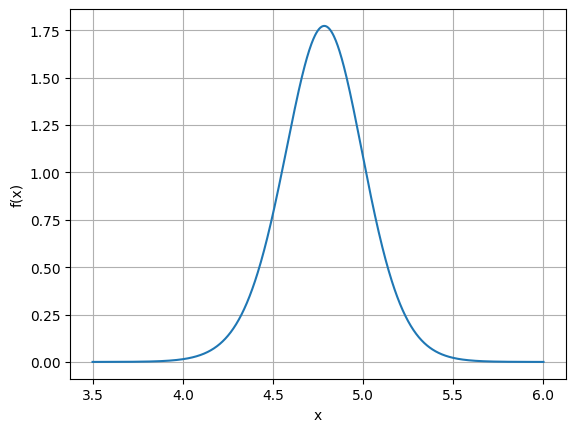

In [4]:
plt.plot(x_array, dens)
plt.grid()
plt.xlabel('x')
plt.ylabel('f(x)')
plt.show()

Since we now have computed the pdf $f$ of $X(T)$, we can now use the pricing-by-integration approach from p. 25 in the lecture notes. In other words, the goal is to numerically compute the integral
\begin{equation} V(0) = B(0) E_Q(g(S(T))/B(T)) = e^{-rT} \int_{-\infty}^\infty g(e^x) f(x) dx, \end{equation}
where $g$ is the payoff function of the option contract under consideration. Since however we only have 1000 discrete samples of the integrand above, we cannot use the scipy function `quad` to compute the above integral.

**Task 1.3**: Define an array `integrand` of length 1000 that contains the values of the integrand $g(e^x) f(x)$ for $x$ taking values in the array `x_array` and $g$ being the payoff of a European call option with strike $K = 100$. Then, use the scipy.integrate function `simpson` to approximate the above integral from the 1000 equidistant samples of the integrand. Store the resulting option price in a variable `call_Heston_int` and print it to the console.

In [5]:
#integrand_coba = np.zeros(len(x_array))
#print(integrand_coba)

#def g_coba(x):
 #   return np.maximum(x - 100, 0)

#for i in range(len(x_array)):
#    integrand_coba[i] = g_coba(np.exp(x_array[i])) * dens[i]

#print(integrand_coba)

#call_Heston_int_coba = np.exp(-r * T) * simpson(y = integrand_coba, x = x_array) 

# y = The function values to integrate (required).
# x = The x-coordinates corresponding to y (optional).

#print(call_Heston_int_coba) # Same result as below, but the below more efficient, because using matrix calculation instead of for loop
# 24.722975470771374


In [6]:
def g(x):
    payoffs = np.maximum(x - 100, 0)
    return payoffs

payoffs = g(np.exp(x_array))
#print(payoffs)
    
integrand = payoffs * dens # g(exp(x)) * f(x)
#print(integrand)

call_Heston_int = np.exp(-r * T) * simpson(y = integrand, x = x_array)
print('Heston call price using the Gil-Pelaez formula: {:.15f}'.format(call_Heston_int))

### Uncomment and execute the following lines only if you obtained no result:
# integrand = np.loadtxt('../shared_materials/objects/4_1_3.txt')
# call_Heston_int = 24.722975470771374 # OK

Heston call price using the Gil-Pelaez formula: 24.722975470771374


<br>

## Step 2: Computation of call option prices in the Black&ndash;Scholes model via Monte Carlo methods

Since option prices are expected values of the form $V(0) = E_Q(e^{-rT} f(S(T))$, we can approximate the expectation on the right-hand side by Monte Carlo simulation. We now want to visualize the convergence of the Monte Carlo estimator for price $V(0)$ of a European call option with strike $K = 100$ and $T=1$ in the Black&ndash;Scholes model with volatility $\sigma=0.3$, initial stock price $S(0)=120$ and risk-free interest rate $r=0.02$ with $M=20$ different trajectories. We want to use up to $N = 10\,000$ simulations of $S(T)$ per trajectory.

**Task 2.1**: Define variables `N` and `M` as specified above. Then, draw $M \times N$ samples of a standard normal distribution and store them in an array `x_rand`. Use the numpy random seed 20 for reproducibility. Finally, compute the 20 different Monte Carlo estimators $\widehat V_N$ (one estimator for each row of `x_rand`) and store them in an array `estimates_N`. Plot the Monte Carlo estimates using the prepared code snippet.

*Useful Python commands*: `rng.normal()`


<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/4_2_1.png" width="550">
</details>

[26.71220433 25.97767932 27.16839196 27.10291909 26.61396239 26.57395182
 26.0902398  26.80137563 26.27180942 27.09288524 27.16037752 26.69913477
 27.26529023 26.27632824 26.75478394 27.27439003 26.33790474 27.47252734
 26.6815672  27.00793668]


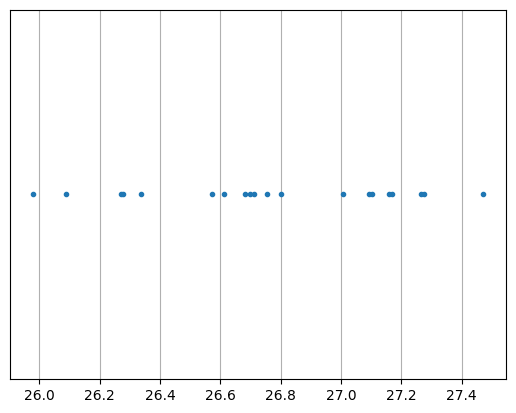

In [7]:
rng = np.random.default_rng(seed=20)
N = 10000
M = 20

x_rand = rng.normal(loc=0, scale=1, size= (M, N))
# print(x_rand)

St = S0 * np.exp((r - (sig_tilde ** 2 / 2)) * T + sig_tilde * np.sqrt(T) * x_rand)
values = np.exp(-r * T) * g(St) # Page 58
estimates_N = np.mean(values, axis = 1) # axis=1 means take the mean across columns (horizontally)
print(estimates_N)


### Uncomment and execute the following lines only if you obtained no result:
x_rand1 = np.loadtxt('../shared_materials/objects/4_2_1a.txt')
estimates_N1 = np.loadtxt('../shared_materials/objects/4_2_1b.txt')

#print(np.array_equal(x_rand, x_rand1)) # All True
#print(np.round(estimates_N, 20) == np.round(estimates_N, 20)) # All True

plt.plot(estimates_N, np.repeat(1, M), '.')
plt.grid()
plt.yticks([])
plt.show()

In [8]:
#pd.DataFrame(x_rand)
pd.DataFrame(estimates_N)

,0
0,26.712204
1,25.977679
2,27.168392
3,27.102919
4,26.613962
5,26.573952
6,26.090240
7,26.801376
8,26.271809
9,27.092885


Instead of only computing twenty different Monte Carlo estimators using $N = 10\,000$ samples, we now want to visually see how the 20 Monte Carlo estimators behave when the number $n$ of samples is varied between $100$ and $N = 10\,000$. We will obtain twenty different *trajectories* of Monte Carlo estimators that should all converge to the true option price as $n$ gets larger.

**Task 2.2.**: Define an array `n` that takes all integer values between $100$ an $N$. Then, define an array `estimates` of shape `(M, N - 99)`. Each row of the array `estimates` is supposed to contain one of the twenty trajectories of Monte Carlo estimators with the number of samples $n$ varying between $100$ and $N$. In other words, the entry `estimates[i, j]` should contain the Monte Carlo estimator $\widehat V_{100 + j}$ of $V(0)$ using the only the simulated elements `x_rand[i, :(99+j)]`.

*Useful Python commands*: `np.arange`, `np.random.normal`, `np.cumsum`

In [9]:
n = np.arange(100, N + 1)
# print(n) OK
estimates = np.zeros((M, N - 99))
# We have M=20 independent trajectories (rows). Each trajectory needs to store the running average 
# for every sample size from 100 to 10,000. 10,000 - 99 = 9,901 columns. This perfectly matches the length of 
# our denominator array n

for i in range(0, M, 1): # Range for 20 rows
    cum_sum = np.cumsum(values[i, :]) # Calculate the cumulatives sum of all values (10000) in each rows
    estimates[i, :] = cum_sum[99:] / n # Only takes from the column 100 to 10000 and take the expectation values

#print(estimates)
#print(cum_sum)

### Uncomment and execute the following lines only if you obtained no result:
n1 = np.loadtxt('../shared_materials/objects/4_2_2a.txt')
estimates1 = np.loadtxt('../shared_materials/objects/4_2_2b.txt')

print(np.array_equal(n, n1)) # True
print(np.round(estimates, 20) == np.round(estimates1, 20)) # Done

True
[[ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]
 ...
 [ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]]


In [10]:
pd.DataFrame(estimates)

,0,1,2,3,4,5,6,7,8,9,...,9891,9892,9893,9894,9895,9896,9897,9898,9899,9900
0,24.244299,25.416478,25.167297,25.261519,25.141515,24.902072,24.953489,24.777698,24.548275,25.170076,...,26.705214,26.707514,26.707597,26.707074,26.708737,26.706065,26.704468,26.707640,26.709679,26.712204
1,31.040904,31.332454,31.025273,30.768869,30.610603,30.319073,30.033044,30.368210,30.087023,30.095469,...,25.973949,25.975962,25.977349,25.974780,25.981671,25.979072,25.979685,25.979721,25.980277,25.977679
2,27.426178,27.339728,27.696351,27.532087,27.267356,27.007667,27.135488,26.881885,27.093437,26.910107,...,27.175780,27.173865,27.171146,27.175414,27.172695,27.169977,27.169223,27.168879,27.171109,27.168392
3,31.986465,32.007699,31.993104,31.682491,31.462049,31.545181,31.316300,31.537639,31.245623,31.793008,...,27.109807,27.107094,27.104381,27.101669,27.099221,27.096510,27.097545,27.098262,27.095552,27.102919
4,23.936614,23.699618,23.557442,23.549407,23.411658,23.484152,23.497262,23.372935,23.292813,23.079118,...,26.607562,26.608072,26.612509,26.609846,26.615161,26.612499,26.612697,26.614162,26.616624,26.613962
5,24.535176,24.407198,24.664977,24.425511,24.829276,24.592807,25.275456,25.640856,25.536509,25.595611,...,26.558877,26.557706,26.555048,26.555363,26.553749,26.558819,26.574670,26.577118,26.574460,26.573952
6,24.320173,24.324133,24.085661,24.049296,25.272921,25.221685,24.983744,24.925112,24.762723,24.748623,...,26.089602,26.086991,26.086182,26.084016,26.081406,26.081826,26.080207,26.084301,26.085564,26.090240
7,26.194515,25.935164,25.680897,25.943004,25.693552,25.876069,26.639388,26.390422,26.620592,26.508827,...,26.811957,26.813104,26.812788,26.810486,26.808174,26.805493,26.802811,26.802719,26.804056,26.801376
8,27.202774,27.023282,27.110379,26.847171,26.589026,26.693125,26.441303,26.984142,26.771514,26.873719,...,26.272382,26.276353,26.280227,26.277598,26.274969,26.273323,26.273690,26.271062,26.272594,26.271809
9,25.608268,25.437837,25.249064,25.590670,25.740658,25.495509,25.402339,25.164934,25.698282,25.500321,...,27.087102,27.088066,27.091491,27.088781,27.088686,27.089160,27.086451,27.085938,27.087521,27.092885


We now want to compare the Monte Carlo estimate option price to the true option price, computed by the Black&ndash;Scholes formula.

**Task 2.3**: Copy your function `european_BS(t, St, K, T, r, sigma, call)` that computes European option prices in the Black&ndash;Scholes model from Task 1.5 of Notebook 02, or write it from scratch if you did not complete that task from week 03. Afterwards, compute the true value of the considered call option price and store it in a variable `true_val`.

In [11]:
def european_BS(t, St, K, T, r, sigma, call):
    
    d1 = (np.log(St/K) + (r + sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))
    
    d2 = (np.log(St/K) + (r - sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))

    # Put-Call-Parity
    if call == 1:
        return St * norm.cdf(d1) - K * np.exp(-r * (T - t)) * norm.cdf(d2)
        
    elif call == 0:
        return K * np.exp(-r * (T - t)) * norm.cdf(-d2) - St * norm.cdf(-d1)

true_val = european_BS(t = 0, St = 120, K = 100, T = 1, r = 0.02, sigma = 0.3, call = 1) # 26.803371450525006 OK

print(true_val)
### Uncomment and execute the following lines only if you obtained no result:
# european_BS = types.FunctionType(marshal.load(open('../shared_materials/objects/2_1_5.mar', 'rb')), globals())
# true_val = 26.803371450525006 # OK

26.803371450525006


One can show that the variance of the discounted payoff $e^{-rT} (S(T) - K)^+$ under $Q$ is approximately $\mathrm{Var}_Q[e^{-rT} (S(T) - K)^+] \approx 1003$. Therefore, the standard deviation of the Monte Carlo estimator with $n \in \{100, \dots, N\}$ samples is approximately given by $\sigma(\widehat V_n) \approx \sqrt{\frac{1003}{n}}$ (see equation (4.2) in the lecture notes). An approximate 95% confidence interval for the Monte Carlo estimate $\widehat V_n$ is therefore given by $\big[V(0) - 1.96 \sqrt{\frac{1003}{n}}, \; V(0) + 1.96 \sqrt{\frac{1003}{n}}\big]$.

**Task 2.4**: Use the array `n` defined in Task 2.2 to compute the above 95% confidence for all the Monte Carlo estimates from the array `estimates` centered at the true value. Store the lower confidence interval boundaries in an array `c_lower` and the upper confidence interval boundaries in an array `c_upper`.

*Useful Python commands*: `np.sqrt`

In [12]:
sigma_sq = 1003
c_lower = true_val - (1.96 * np.sqrt(sigma_sq / 100))
c_upper = true_val + (1.96 * np.sqrt(sigma_sq / n))

print(c_lower)
print(c_upper)

### Uncomment and execute the following line only if you obtained no result:
#c_lower1, c_upper1 = np.loadtxt('../shared_materials/objects/4_2_4.txt')

#print(np.array_equal(c_lower, c_lower1)) # True
#print(np.array_equal(c_upper, c_upper1)) # True

20.596017102656667
[33.0107258  32.97991988 32.94956811 ... 27.42416897 27.42413792
 27.42410689]


**Task 2.5**: Plot the 20 trajectories of Monte Carlo estimates from the array `estimates` against the number of sample paths from the array `n`. Additionally draw the upper and lower confidence interval boundaries from the arrays `c_lower` and `c_upper` into the same plot window. Finally, use the function `plt.axhline` to draw a horizontal line at the true option value `true_val` and interpret your result using a comment.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/4_2_5.png" width="550"><details>
  <summary>Interpretation:</summary> The 20 Monte Carlo trajectories are converging towards the true option price given in red as the number $N$ of simulations is increased. Most of the variability of the Monte Carlo estimates can be captured by the 95% confidence intervals, which are given as black dotted lines. The width of these confidence intervals decreases proportionally to $1 / \sqrt{N}$, indicating the slow convergence of the Monte Carlo estimates.

 </details>
</details>

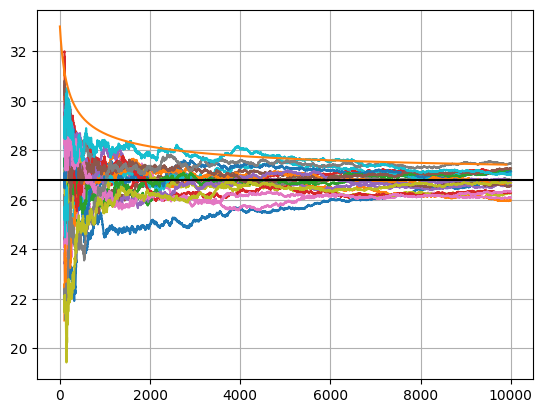

In [13]:
for i in range(M):
    plt.plot(n, estimates[i, :])
    
plt.plot(c_lower)
plt.plot(c_upper)
plt.axhline(true_val, color = 'black')
plt.grid()
plt.show()

# Interpretation: The 20 Monte Carlo trajectories are converging towards the true option price given in black as the number 
# of simulations is increased. Most of the variability of the Monte Carlo estimates can be captured by the 95% confidence intervals, 
# which are given as black dotted lines. The width of these confidence intervals decreases proportionally to, 
# indicating the slow convergence of the Monte Carlo estimates.

<br><br>

## Step 3: Computation of chooser option prices in the Black-Scholes model via Monte Carlo methods

A chooser option with expiry at time $T$ and strike $K$ is an option contract that grants the holder of the option the possibility to choose at some prespecified time $t^∗ \in (0, T)$ whether the option should be a call option or a put option with strike $K$. Our goal is now to use Monte Carlo methods to compute the price $V(0)$ of a chooser option with expiry at time $T=1$ and strike $K=100$ in the Black-Scholes model and compare it with the theoretical true value. In our case, the choosing time is set to $t^* = 0.5$. If at this time point the theoretical price of a European call option with expiry at $T$ is higher than the theoretical price of a European put option with expiry at $T$, then the holder of the chooser option will decide that it will be a call option at expiry, and vice versa.

The code snippet below imports $N = 10\,000$ independent paths of a geometric Brownian motion $S(t) = S(0) \exp((r - \sigma^2 / 2) t + \sigma W(t))$ with $r = 0.02$ and $\sigma = 0.3$ at the $M = 1000$ time points $t = t_i = 0, \frac{1}{1000}, \frac{2}{1000}, \dots, \frac{999}{1000}, 1$.

In [14]:
t_star = 0.5
stock_paths = np.loadtxt('../shared_materials/data/GBM_paths.csv')
N = stock_paths.shape[0]
M = stock_paths.shape[1]
print(N)
print(M)
print(stock_paths.shape)

10000
1001
(10000, 1001)


In [15]:
pd.DataFrame(stock_paths)

,0,1,2,3,4,5,6,7,8,9,...,991,992,993,994,995,996,997,998,999,1000
0,120.0,120.963982,122.275279,121.722363,120.727033,119.796215,119.988886,119.932533,121.255797,120.030700,...,87.303571,87.762587,87.488876,88.096548,89.775204,89.142800,88.887064,89.649018,90.573346,89.510699
1,120.0,119.322806,119.988427,119.851981,120.456731,121.734136,121.925958,124.044662,125.224632,126.217745,...,135.324713,136.667592,135.162910,135.075591,136.259262,136.987559,136.796304,138.431464,138.248365,136.928374
2,120.0,121.473178,120.797558,120.631579,121.085333,122.854581,122.334112,123.375939,122.158921,121.413581,...,96.267720,94.499436,94.414851,94.431609,94.459644,92.814027,93.627999,92.223193,93.756877,94.058832
3,120.0,120.087260,119.454077,119.390680,119.051873,118.125164,116.816414,117.568726,118.317728,120.301368,...,71.966818,71.988537,71.614809,71.368910,70.644226,71.122926,72.452958,71.340348,70.272703,69.683412
4,120.0,119.312767,119.143455,118.850451,117.827626,118.289631,116.580301,116.215465,116.393426,117.771647,...,153.975128,153.747691,153.667029,153.835432,153.638375,152.994412,154.257373,154.423788,154.751197,155.806992
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,120.0,121.213623,121.298178,120.564887,119.635972,118.926251,118.449990,119.550507,120.323154,123.548948,...,137.592522,137.063783,137.354622,134.197809,133.820433,135.014728,133.323586,132.813039,133.076881,133.057527
9996,120.0,119.337228,119.345449,118.826392,119.498422,118.358861,119.369827,119.641085,122.101813,122.539661,...,110.125429,110.537518,111.713704,110.416957,110.846288,110.598383,110.632029,111.004183,110.134928,110.943482
9997,120.0,119.981584,119.594981,118.702654,119.064336,116.911434,118.930298,119.588733,119.780689,118.955556,...,68.231903,68.314925,68.498544,68.925808,67.172412,67.724606,66.345864,66.451315,66.206606,65.768004
9998,120.0,120.702818,122.134835,120.789350,120.503043,118.952115,119.684986,116.811321,117.016374,115.992671,...,181.728314,181.305449,180.928419,180.890012,180.591874,179.828542,181.433651,181.231471,180.306782,182.838094


To compute chooser option prices via Monte Carlo methods, we have to check for each of the $N = 10\,000$ stock price paths whether a European call option or a European put option with expiry at $T=1$ has a higher value at time $t^* = 0.5$. If the call option value is higher, then the chooser option will also be a call at expiry, if the put option value is higher, then the chooser option will be a put at expiry.

**Task 3.1**: Use your function `european_BS` to compute the call option prices at time $t^*=0.5$ for each of the $N=10\,000$ stock price paths with $r=0.02$ and $\sigma=0.3$. Store the resulting call prices in an array `call_prices_mid`. Repeat this for the put option prices at time $t^*=0.5$ and store them in an array `put_prices_mid`.

In [16]:
mid_price = stock_paths[:, 500]
# Since there are 1001 total time steps (0 to 1 with step 1/1000), t* = 0.5 is at index 500
# Why not at index 499? Karna S0 gak di itung? (karna 500 itu index, not a range)

call_prices_mid = european_BS(t_star, mid_price, K, T, 0.02, 0.3, call = 1)
put_prices_mid = european_BS(t_star, mid_price, K, T, 0.02, 0.3, call = 0)
print(put_prices_mid)
print(call_prices_mid)
### Uncomment and execute the following line only if you obtained no result:
call_prices_mid1, put_prices_mid1 = np.loadtxt('../shared_materials/objects/4_3_1.txt')
print(call_prices_mid1)
print(put_prices_mid1)

print(np.round(call_prices_mid, 20) == np.round(call_prices_mid1, 20)) # OK
print(np.round(put_prices_mid, 10) == np.round(put_prices_mid1, 10)) # OK

[10.65153222  0.88670865  1.92082819 ... 18.48246903  1.39573909
  0.92705028]
[ 6.08978575 35.1696627  25.45011306 ...  2.09034443 29.45641116
 34.60955343]
[ 6.08978575 35.1696627  25.45011306 ...  2.09034443 29.45641116
 34.60955343]
[10.65153222  0.88670865  1.92082819 ... 18.48246903  1.39573909
  0.92705028]
[ True  True  True ...  True  True  True]
[ True  True  True ...  True  True  True]


**Task 3.2**: Initialize an array `payoffs` of length $N = 10\,000$ that contains only zeros. Then, at the indices of all stock price paths for which the call price at $t^*=0.5$ is higher than the put price, set the corresponding element in the array `payoffs` to the payoff of a European call option at time $T=1$ with strike $K$. Likewise, at the indices of all stock price paths for which the put price at $t^*=0.5$ is higher than the call price, set the corresponding element in the array `payoffs` to the payoff of a European put option at time $T=1$ with strike $K$.

*Useful Python commands*: `np.zeros`, `np.maximum`

In [17]:
payoffs = np.zeros(N)
print(len(payoffs))

S_T = stock_paths[:, 1000]

for i in range(0, N, 1):
    if call_prices_mid[i] > put_prices_mid[i]:
        payoffs[i] = np.maximum(S_T[i] - K, 0)
    else:
        payoffs[i] = np.maximum(K - S_T[i], 0)

print(payoffs)

### Uncomment and execute the following line only if you obtained no result:
payoffs1 = np.loadtxt('../shared_materials/objects/4_3_2.txt')
print(payoffs1)

print(np.array_equal(payoffs, payoffs1)) # True

10000
[10.48930121 36.92837438  0.         ... 34.23199587 82.83809378
 14.2861831 ]
[10.48930121 36.92837438  0.         ... 34.23199587 82.83809378
 14.2861831 ]
True


**Task 3.3**: Compute the Monte Carlo estimate $\widehat V_N$ of the chooser option price as the discounted average of all the payoffs in the array `payoffs` and store it in a variable `chooser_price`. Afterwards, compute the sample variance $\widehat \sigma^2_N(f(X))$ of the discounted payoffs (see equation (4.5) in the lecture notes) and store it in a variable `sigma_sq`. Compute also the lower and upper boundary of an approximate 95% confidence interval $[\widehat V_n - 1.96 \sqrt{\widehat \sigma^2_N(f(X)) / N},\; \widehat V_n + 1.96 \sqrt{\widehat \sigma^2_N(f(X)) / N}]$ of the chooser option price and store them in variables `c_lower` and `c_upper`.

*Useful Python commands*: `np.exp`, `np.mean`, `np.var`, `np.sqrt`.

In [18]:
chooser_price = np.exp(-r * T) * np.mean(payoffs)
print(chooser_price) # OK
sigma_sq = np.var(np.exp(-r * T) * payoffs, ddof=1)
# sigma_sq = np.exp(-r * T) * (1 / (N - 1) * (np.sum((payoffs - chooser_price) ** 2)))
# Setting ddof=1 (Delta Degrees of Freedom) changes that denominator from N to N - 1
print(sigma_sq) 
c_lower = chooser_price - (1.96 * np.sqrt(sigma_sq / N))
c_upper = chooser_price + (1.96 * np.sqrt(sigma_sq / N))
print(c_lower) # OK
print(c_upper) # OK


### Uncomment and execute the following line only if you obtained no result:
# chooser_price, sigma_sq, c_lower, c_upper = 28.770057344351816, 920.9695874595875, 28.175246721784873, 29.36486796691876

28.770057344351816
920.9695874595876
28.175246721784873
29.36486796691876


**Task 3.4**: Use your function `european_BS` and the result from Theoretical Exercise 06.1 on Homework Sheet 06 to compute the true theoretical price of the chooser option in the Black-Scholes model and store it in a variable `true_price`. Afterwards, print the Monte Carlo estimate `chooser_price`, the confidence interval [`c_lower`, `c_upper`] and the true price `true_price`.

In [19]:
true_price = european_BS(0, S0, K, T, r, sigma, call = 1) + european_BS(0, S0, K * np.exp(-r * (T - t_star)), t_star, r, sigma, call = 0)
print('MC chooser option price: {:.15f}, 95%-CI: [{:.3f}, {:.3f}], True price: {:.15f}'.format(chooser_price, c_lower, c_upper, true_price))

### Uncomment and execute the following line only if you obtained no result:
# true_price = 28.887698227157014 # OK

MC chooser option price: 28.770057344351816, 95%-CI: [28.175, 29.365], True price: 28.887698227157014


<br>

## Step 4: Random number generation via inversion

Generating random numbers from a distribution with cumulative distribution function (cdf) $F$ is straightforward using the inversion method if the inverse function $F^{-1}$ is known in closed form. We now want to apply the inversion method to simulate $N = 1000$ independent samples of a *Rayleigh distribution* with scale parameter $\sigma = 3$. A Rayleigh distribution $\mathrm{Ray}(\sigma)$ with scale parameter $\sigma$ has the probability density function (pdf) $f(x) = (x/\sigma^2) e^{-x^2 / (2\sigma^2)}$ and the cdf $F(x) = 1 - e^{-x^2 / (2\sigma^2)}$ for $x \in [0, \infty)$. The inverse of this cdf is given by $F^{-1}(u) = \sqrt{-2 \sigma^2 \log(1 - u)}$ for $u \in [0, 1)$.

In the code snippet below, we initialized an instance of a `rayleigh` object with scale 3 from the scipy.stats module. It will be used in the following tasks to compute the pdf of a Rayleigh distribution with scale parameter $\sigma = 3$.

**Task 4.1**: Draw $N = 1000$ samples from the uniform distribution on $[0, 1]$ and store them in an array `U`. Use the numpy random seed 20 to get comparable results. Then, transform these random variables using the inverse cdf of the target Rayleigh distribution to obtain samples from it and store these in an array `rayleigh_samples`.

*Useful Python commands*: `rng.uniform`

In [20]:
sigma_scale = 3
N = 1000
f = rayleigh(scale=sigma_scale)

rng = np.random.default_rng(seed=20)
U = rng.uniform(low = 0, high = 1, size = N)
rayleigh_samples = np.sqrt(-2 * (sigma_scale ** 2) * np.log(1 - U))
print(rayleigh_samples)

### Uncomment and execute the following line only if you obtained no result:
U1, rayleigh_samples1 = np.loadtxt('../shared_materials/objects/4_4_1.txt')
#print(np.array_equal(U1, U)) # True
print(np.array_equal(rayleigh_samples1, rayleigh_samples)) # True

[ 2.43207162  3.33610773  1.52846676  3.64822218  3.0776674   1.15673404
  1.36961113  8.78698972  4.6172564   3.2738653   4.28935485  2.38261441
  2.5433052   1.17092876  0.98607092  5.44568992  5.49627643  0.29951998
  2.68515979  1.29597034  3.37019524  4.16021601  3.79672358  1.60964367
  4.67104706  4.13358532  3.36757775  2.51921151  6.71604938  1.25231526
  1.67773227  2.92629423  2.32400992  4.15184997  4.62035755  4.68045923
  5.17309315  1.86221652  4.96888713  2.25470609  3.71776383  2.12113162
  5.48638017  1.43355338  3.18506171  4.25186511  4.63870241  1.34317077
  8.63528484  2.48250792  3.26239976  2.5536104   0.85609668  2.2466753
  2.66987156  3.92545835  1.13923241  6.93338116  1.99752948  3.68343212
  2.81565938  2.83122814  6.6009881   6.29335528  4.11916928  2.43040258
  1.73989263  3.35715107  1.82965283  3.51718987  1.14817894  0.55196156
  3.69436114  2.99493317 10.05930105  2.90627521  3.70008238  2.98115716
  5.17147815  2.92120438  2.31282897  3.3156471   5.

**Task 4.2**: Draw a histogram of the samples `rayleigh_samples` with 30 bins. Then, initialize an array `x_array` that contains 1000 equally spaced values between 0 and 12 and use the method `f.pdf(...)` of your `rayleigh` object from Task 4.1 on the `x_array` to compute the pdf of the $\mathrm{Ray}(3)$ distribution on $(0, 12)$ and plot it in the same plot window.

*Useful Python commands*: `plt.hist`. Specify the argument `density=True` in the `plt.hist` function to get a histogram that has heights compatible with the pdf.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/4_4_2.png" width="550">
</details>

True


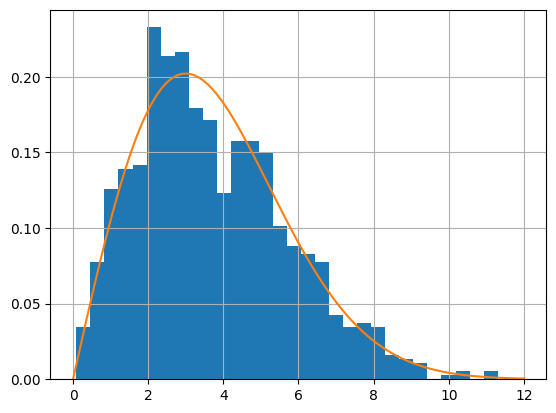

In [21]:
plt.hist(rayleigh_samples, density = True, bins = 30)
x_array = np.linspace(0, 12, 1000)

rayleigh = f.pdf(x_array)
plt.plot(x_array, rayleigh)
plt.grid()

### Uncomment and execute the following line only if you obtained no result:
x_array1 = np.loadtxt('../shared_materials/objects/4_4_2.txt')

print(np.array_equal(x_array, x_array1)) # True

plt.show()

In some applications, one has just access to values $F(x_i)$ of the cdf of a distribution for equidistant values $x_1 < x_2 < \dots < x_n$ without knowing the inverse cdf analytically. In these cases, one can still numerically approximate the inverse cdf by linear interpolation: Suppose you want to evaluate $F^{-1}(u)$ for some $F(x_1) \leq u \leq F(x_n)$. Then, one can find $x_{i-1}$ and $x_i$ such that $F(x_{i-1}) \leq u \leq F(x_i)$ and approximate $F^{-1}(u)$ by linearly interpolating $x_{i-1}$ and $x_i$, i.e. by \begin{equation}\frac{x_{i-1} (F(x_i) - u) + x_i (u - F(x_{i-1}))}{F(x_i) - F(x_{i-1})}.\end{equation}

**Task 4.3**: Write a function `inverse_sampling(x_array, F, N, seed)` takes as inputs an array `x_array`of equidistant points $x_i$ as well as an array `F` of corresponding cdf values $F(x_i)$ and uses the above methodology to draw $N$ samples from the distribution with cdf $F$. Your function should first draw $N$ samples from the uniform distribution on $[0, 1]$ and then use the function `np.interp` to perform the above interpolation. Your function should also accept an argument `seed` to specify a random seed that the sampler uses.

*Useful Python commands*: To linearly interpolate the values $y_i = f(x_i)$ with $y_i$ and $x_i$ given by arrays `y` and `x`, respectively, onto some values $x_i^*$ given in an array `x_target`, one can use the command `np.interp(x_target, x, y)`.

In [22]:
def inverse_sampling(x_array, F, N, seed):
    rng = np.random.default_rng(seed=seed)
    # 1. Draw N samples from a Uniform(0, 1) distribution
    U = rng.uniform(low = 0, high = 1, size = N)
    # 2. Use linear interpolation to find the corresponding x-values
    return np.interp(U, F, x_array)

F = 1 - np.exp(-x_array**2 / (2 * (sigma_scale**2)))

F_inverse = inverse_sampling(x_array, F, N, 20)
#print(F_inverse)


### Uncomment and execute the following line only if you obtained no result:
#inverse_sampling1 = types.FunctionType(marshal.load(open('../shared_materials/objects/4_4_3.mar', 'rb')), globals())
#print(inverse_sampling1(x_array, F, N))

In [23]:
# 1. The Core Logic: Numerical InversionNormally, to sample from a distribution, you generate a uniform random number $u \in [0, 1]$
# and find $x$ such that $F(x) = u$. If you can't solve for $x$ algebraically, you use the discrete points you do have $(x_i, F(x_i))$ 
# to estimate it.The formula provided is a standard Linear Interpolation:
# $$\frac{x_{i-1}(F(x_i) - u) + x_i(u - F(x_{i-1}))}{F(x_i) - F(x_{i-1})}$$
# What it's doing: It finds the two closest known CDF values that "sandwich" your random number $u$ 
# (where $F(x_{i-1}) \leq u \leq F(x_i)$).Weighted Average: It treats the distance between those two points as a straight line. 
# If $u$ is closer to $F(x_i)$, the result will be closer to $x_i$.


# Why the order in np.interp matters:Usually, we think of functions as $y = f(x)$. But for the Inverse CDF, 
# we are treating the probabilities ($F$) as the "input" and the values ($x$) as the "output."U: 
# These are the values we want to evaluate (the "targets").F: These are the known "x-coordinates" (the CDF values).x_array: 
# These are the known "y-coordinates" (the values from the distribution).

**Task 4.4**: The code snippet below contains an array `F` with values $F(x_i)$, where $x_i$ are the equally spaced values from the array `x_array` and $F$ is the cdf of the $\mathrm{Ray}(3)$ distribution. Draw 1000 samples of the $\mathrm{Ray}(3)$ distribution using the array `F` together with your function `inverse_sampling` from Task 4.3 and repeat Task 4.2 with these new samples. Use the numpy random seed 20 again.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/4_4_4.png" width="550">
</details>

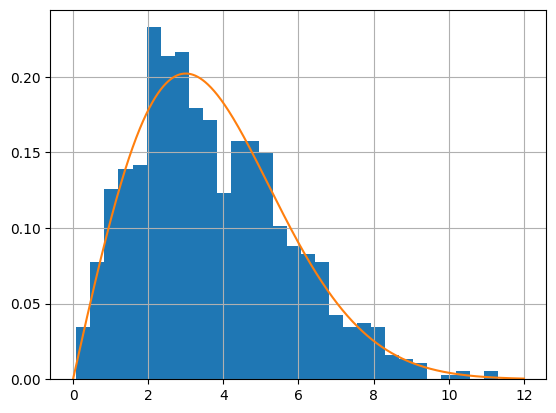

In [24]:
F_more = inverse_sampling(x_array, F, 1000, 20)
plt.hist(F_more, density = True, bins = 30)
plt.plot(x_array, rayleigh)
plt.grid()

plt.show()

<br>

## Step 5: Random number generation via the acceptance/rejection method

When the pdf of a distribution that one wants to sample from is known analytically, one can apply the acceptance/rejection method to sample from that distribution. We now want to apply this method to sampling from the $\mathrm{Ray}(3)$ distribution. Let $f$ denote the density of the $\mathrm{Ray}(3)$ distribution and let $g$ be the auxiliary density of an $\mathrm{Exp}(1)$ distribution, an exponential distribution with parameter 1. In the code snippet below, we initialize an instance of an `expon` object from the scipy.stats module that represents this distribution. We then have to find a suitable constant $C$ such that $f(x) \leq C g(x)$. Since $C$ is supposed to be not too large, we want to take the smallest possible value $C$ that satisfies this inequality. This smallest possible value is given by $C = \max_x \frac{f(x)}{g(x)}$ and is determined numerically in the code snippet below (we compute it as $C = - \min_x -\frac{f(x)}{g(x)}$ because scipy is only able to numerically minimize a function).

In [25]:
g = expon(scale=1)
C = -minimize(lambda x: -f.pdf(x) / g.pdf(x), x0=1).fun
# x0 represents the initial guess (the starting point) where the computer begins its search for the minimum or maximum value. 
# .fun extracts the function value (the $y$-axis value) at that lowest point. SciPy returns a negative number here.
print(C)

94.66216402227681


**Task 5.1**: We now want to perform the acceptance/rejection method. Fill in the blank spaces in the code below that is supposed to draw $N$ samples from the $\mathrm{Ray}(3)$ distribution with pdf $f$. The variable `num_trials` is supposed to count the total number of simulated random variables $Y$ (no matter whether they were rejected or accepted as a simulation of $X \sim \mathrm{Ray}(3)$) that were necessary to obtain $N$ samples from the $\mathrm{Ray}(3)$ distribution.

*Useful Python commands*: A single random variable with target density $g$ can be simulated using the command `g.rvs()`. The pdf's $f(\dots)$ and $g(\dots)$ can be evaluated using `f.pdf(...)` and `g.pdf(...)`, respectively.

In [26]:
num = 0
num_trials = 0
samples_accrec = np.zeros(N)
rng = np.random.default_rng(seed=20)
while num < N: # The loop keeps running until you have successfully collected exactly $N$ (in this case, 1,000) accepted samples.
    Y = g.rvs(random_state=rng) # This generates a candidate value $Y$ from your easy-to-sample proposal distribution g.
    U = rng.uniform(0,1) # This generates a random baseline height between 0 and 1 to determine whether the candidate is accepted.
    if U <= f.pdf(Y) / (C * g.pdf(Y)): 
# This is the mathematical gatekeeper. The ratio f(Y) / C g(Y) represents the probability of accepting Y. 
# If your random number U falls below this threshold, the candidate is accepted, saved into samples_accrec, 
# and the num counter ticks up.
        samples_accrec[num] = Y # Saving your successful candidate into your storage box
        num += 1
    num_trials += 1
    
# Notice this sits outside the if statement. It increments on every single iteration of the loop because it tracks the total number 
# of attempts made, whether they were accepted or rejected.

print(len(samples_accrec))

print('Necessary number of simulated random variables Y: {}'.format(num_trials))

# The algorithm had to generate 93,739 candidates just to get 1,000 good samples.
# While the math is perfectly accurate, a 1% acceptance rate is computationally very expensive. 
# It tells us that the blanket distribution Cg(x) is much larger than the target distribution f(x), 
# meaning the algorithm spent 99% of its time throwing away bad data.


### Uncomment and execute the following line only if you obtained no result:
# num_trials = 93739

1000
Necessary number of simulated random variables Y: 93739


**Task 5.2**: Repeat Task 4.2 for the samples in the array `samples` from Task 5.1, obtained via the acceptance/rejection method.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/4_5_2.png" width="550">
</details>

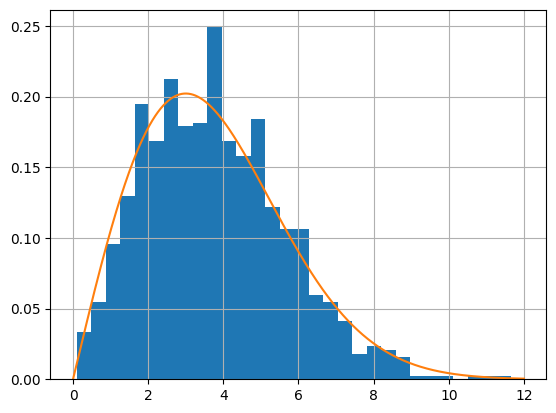

In [27]:
plt.hist(samples_accrec, density = True, bins = 30)
x_array = np.linspace(0, 12, 1000)

rayleigh = f.pdf(x_array)
plt.plot(x_array, rayleigh)
plt.grid()

plt.show()

**Task 5.3**: Write a function `sample_acc_rec(f, g, N, seed)` that performs the whole acceptance/rejection method in total. The function should receive input arguments `f` and `g` that stand for the target distribution and the auxiliary distribution, respectively (`f` should be callable with method `f.pdf(...)` and `g` should be callable with methods `g.pdf(...)` and `g.rvs()` in order for the code from Task 5.1 to work), as well as an input argument `N` for the desired number of samples. The function should first instantiate an `rng` instance with random seed `seed`. Then it should determine the value of `C` as above an then perform the while-loop as in Task 5.1. It should then return both the simulated samples as well as the total number of simulated random variables $Y$. 

In [28]:
def sample_acc_rej(f, g, N, seed):
    C = -minimize(lambda x: -f.pdf(x) / g.pdf(x), x0=1).fun
    
    num = 0
    num_trials = 0
    samples_accrec = np.zeros(N)
    rng = np.random.default_rng(seed=seed)
    while num < N:
        Y = g.rvs(random_state=rng)
        U = rng.uniform(0,1)
        if U <= f.pdf(Y) / (C * g.pdf(Y)):
            samples_accrec[num] = Y
            num += 1
        num_trials += 1
    return samples_accrec, num_trials

reject = sample_acc_rej(f, g, 1000, 20)
print(reject) # OK, 93739 number of trials

### Uncomment and execute the following line only if you obtained no result:
#sample_acc_rej1 = types.FunctionType(marshal.load(open('../shared_materials/objects/4_5_3.mar', 'rb')), globals())

#reject1 = sample_acc_rej1(f, g, 200, 20)
#print(reject1)

#print(np.round(reject, 10) == np.round(reject1, 10))

(array([ 2.35512711,  2.68077714,  2.81163376,  4.23478168,  1.50541231,
        3.33226594,  2.28283342,  2.59006199,  4.51928321,  4.1728118 ,
        7.1725886 ,  4.43515211,  4.7519213 ,  3.68593797,  3.12551723,
        4.52126404,  3.45435795,  4.38036356,  9.31068089,  3.24925402,
        8.25156432,  3.70951468,  3.29826425,  2.05684876,  0.6895455 ,
        5.20361278,  1.02546198,  1.18068207,  2.98429078,  1.7143588 ,
        6.51953753,  4.00778879,  4.8874916 ,  6.06114482,  1.54244703,
        3.16811519,  3.79903841,  1.67089006,  5.28231849,  5.16009356,
        3.40453557,  2.75693415,  4.51646548,  4.40504164,  5.85297275,
        2.78515587,  2.68033086,  2.46823046,  3.8658132 ,  1.25019825,
        5.93420252,  1.42415368,  3.43359173,  6.4009126 ,  5.77583639,
       11.66692945,  7.09170042,  4.21736464,  0.79770888,  1.07171955,
        4.74670839,  0.85245445,  1.71860129,  2.56020046,  8.67847026,
        3.70659781,  3.99430524,  2.41696962,  1.99756318,  2.3

If you worked with the numpy random seed 20 in Task 5.1, you should be able to see that a total of $93\,739$ simulations of a random variable $Y \sim \mathrm{Exp}(1)$ where necessary to obtain only 1000 samples of the $\mathrm{Ray}(3)$ distribution. Computationally, this is highly inefficient. The reason for this is that the $\mathrm{Exp}(1)$ distribution is not a very suitable auxiliary distribution to sample from the $\mathrm{Ray}(3)$ distribution.

From the calculations on page 52 in the lecture notes one can see that the probability of accepting a simulation $Y \sim g$ as a simulation of $X \sim f$ (i.e. the probability $P(U \leq f(Y)/(Cg(Y)))$ is given by $1 / C$. To make the acceptance/rejection method efficient, we want to reject as few samples $Y$ as possible, so we want the probability $1 / C$ to be large, or in other words, we want $C$ to be as small as possible. In the code above, we determined the optimal value of $C$ for the distribution $\mathrm{Exp}(1)$ with density $g$ as $\max_x \frac{f(x)}{g(x)}$. Now we want to find the smallest possible value of these constants $C$ by varying the scale parameter $s$ of the $\mathrm{Exp}(s)$ distribution. In other words, if $g_s$ denotes the density of the $\mathrm{Exp}(s)$ distribution, we want to determine $s = \mathrm{arg} \min_{s > 0} \max_x \frac{f(x)}{g_s(x)}$.

**Task 5.4**: Determine the above optimal $s$ using the scipy function `minimize`, store it in a variable `scale_opt` and print it.

*Useful Python commands*: The optimum $\max_x \frac{f(x)}{g_s(x)}$ can be computed using the scipy.optimize command `-minimize(lambda x: -f.pdf(x) / expon(scale=s).pdf(x), x0=1).fun`.

In [29]:
# "If I choose an Exponential distribution with scale $s$, what is the smallest constant c I can use to fully cover 
# the Rayleigh distribution?"
opt_max = lambda s: -minimize(lambda x: -f.pdf(x) / expon(scale=s).pdf(x), x0 = 1).fun
print(opt_max)
# .fun: This extracts the optimal objective value achieved at that maximum point, which represents -c(s).
res = minimize(opt_max, x0 = 1)
scale_opt = res.x[0] # The final value of the objective function at the minimum and extracts the float value: 4.24264126
print(res)
print(scale_opt)

### Uncomment and execute the following line only if you obtained no result:
# scale_opt = 4.242641260036824 # OK

<function <lambda> at 0x7f517d9984a0>
  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 2.0000000000000235
        x: [ 4.243e+00]
      nit: 12
      jac: [ 8.941e-08]
 hess_inv: [[ 6.730e+00]]
     nfev: 30
     njev: 15
4.242641260036824


**Task 5.5**: Use your function `sample_acc_rej` to simulate $N = 1000$ samples from the $\mathrm{Ray}(3)$ distribution using the optimal auxiliary density $g_s$ with $s$ given by `scale_opt`. Use the numpy random seed 20 for reproducibility. Print the number of simulated random variables $Y$ in this case and compare it to the number obtained in Task 5.1.

In [33]:
f = rayleigh(scale=3)
g_opt = expon(scale=scale_opt)

better = sample_acc_rej(f, g_opt, 1000, 20) # Ngitung pake g_opt, instead of g
print(better[1]) # Only print the number of trials, samples_accrec nya gak usah

### Uncomment and execute the following line only if you obtained no result:
# num_trials = 1978

1978
